In [1]:
# Magnificent 7 return baskets: Mag7, Mag7B and Mag7C (Section 3.2.3)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The clean files are saved straight into the folder with the regression notebooks
OUT = "../Regressions and relevant csvs/"

In [2]:
# Compustat Security Monthly (WRDS): monthly total return (trt1m, in percent) of the seven stocks,
# December 2015 to December 2025
raw = pd.read_csv("Mag7 Monthly Returns.csv")
stocks = pd.DataFrame({
    "ticker": raw["(tic) Ticker Symbol"],
    "date": pd.to_datetime(raw["(datadate) Data Date - Security Monthly"], format="%d.%m.%Y"),
    "ret": raw["(trt1m) Monthly Total Return"] / 100,
})
stocks["log_ret"] = np.log(1 + stocks["ret"])

# One column per stock
wide = stocks.pivot(index="date", columns="ticker", values="log_ret")
print(len(wide), "months, missing values:", wide.isna().sum().sum())

121 months, missing values: 0


In [3]:
# Equal-weighted baskets of the log returns
mag7 = ["AAPL", "AMZN", "GOOGL", "META", "MSFT", "NVDA", "TSLA"]
mag7b = ["AAPL", "AMZN", "GOOGL", "META", "MSFT", "NVDA"]      # without Tesla
mag7c = ["GOOGL", "META", "MSFT", "NVDA"]                      # AI-focused core

baskets = pd.DataFrame({
    "mag7_ret": wide[mag7].mean(axis=1),
    "mag7b_ret": wide[mag7b].mean(axis=1),
    "mag7c_ret": wide[mag7c].mean(axis=1),
}).reset_index()
baskets.describe()

,date,mag7_ret,mag7b_ret,mag7c_ret
count,121,121.000000,121.000000,121.000000
mean,2020-12-29 23:24:17.851239680,0.022908,0.022074,0.024312
min,2015-12-31 00:00:00,-0.197029,-0.194346,-0.198178
25%,2018-06-30 00:00:00,-0.021196,-0.013420,-0.012322
50%,2020-12-31 00:00:00,0.026927,0.029586,0.028648
75%,2023-06-30 00:00:00,0.075163,0.069296,0.073412
max,2025-12-31 00:00:00,0.200230,0.161002,0.164388
std,NaN,0.073652,0.068117,0.072338


In [4]:
m = baskets.set_index("date")["mag7_ret"]
print("Largest gains:", ", ".join(f"{v:+.1%} ({d:%b %Y})" for d, v in m.nlargest(3).items()))
print("Largest losses:", ", ".join(f"{v:+.1%} ({d:%b %Y})" for d, v in m.nsmallest(2).items()))
baskets.drop(columns="date").corr().round(3)

Largest gains: +20.0% (Aug 2020), +19.5% (Apr 2020), +18.6% (Jan 2023)
Largest losses: -19.7% (Apr 2022), -15.0% (Dec 2022)


,mag7_ret,mag7b_ret,mag7c_ret
mag7_ret,1.000,0.959,0.914
mag7b_ret,0.959,1.000,0.974
mag7c_ret,0.914,0.974,1.000


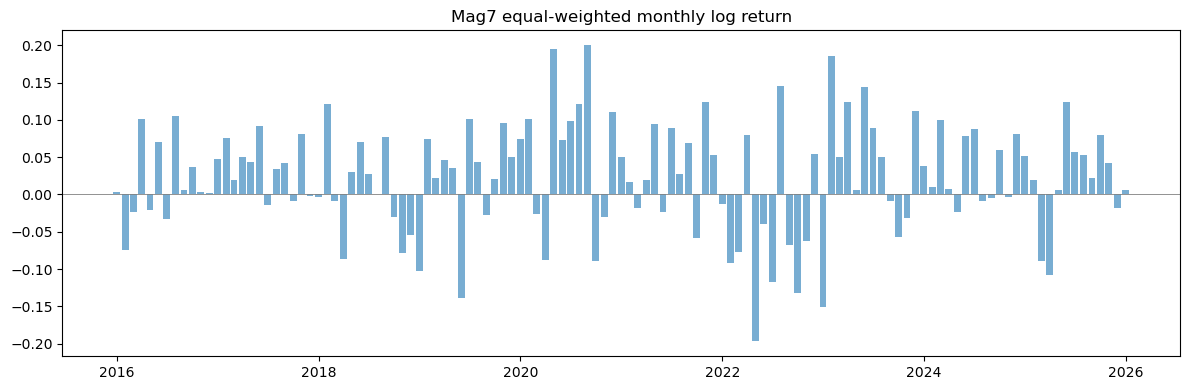

In [5]:
plt.figure(figsize=(12, 4))
plt.bar(baskets["date"], baskets["mag7_ret"], width=25, alpha=0.6)
plt.axhline(0, color="grey", lw=0.6)
plt.title("Mag7 equal-weighted monthly log return")
plt.tight_layout()
plt.show()

In [6]:
baskets[["date", "mag7_ret"]].to_csv(OUT + "mag7_clean.csv", index=False)
baskets[["date", "mag7b_ret"]].to_csv(OUT + "mag7b_clean.csv", index=False)
baskets[["date", "mag7c_ret"]].to_csv(OUT + "mag7c_clean.csv", index=False)